In [ ]:
%pip install --upgrade "scikit-learn>=1.9.1" pandas matplotlib

In [22]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold,
)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)

if tuple(int(part) for part in sklearn.__version__.split(".")[:2]) < (1, 6):
    raise RuntimeError(
        "This notebook requires a recent scikit-learn version with native "
        "pandas categorical support. Run the installation cell and restart the kernel."
    )

Python: 3.15.2 (tags/v3.15.2:5e58eaa, Oct 25 2026, 17:27:03) [MSC v.1951 64 bit (AMD64)]
Python executable: c:\Users\aly0m\AppData\Local\Programs\Python\Python315\python.exe
scikit-learn: 1.9.1
pandas: 3.1.0


In [23]:
# The notebook first checks the same folder, then common project locations.
candidates = [
    Path("H2_cleaned.csv"),
    Path("data") / "processed" / "H2_cleaned.csv",
]

# This supports a notebook located at:
# Machine-Learning/src/hotel_booking/classification/
try:
    candidates.append(Path.cwd().parents[2] / "data" / "processed" / "H2_cleaned.csv")
except IndexError:
    pass

DATA_PATH = next((path for path in candidates if path.exists()), None)

if DATA_PATH is None:
    searched = "\n".join(str(path.resolve()) for path in candidates)
    raise FileNotFoundError(
        "Could not find H2_cleaned.csv. Put it beside this notebook or in "
        "the project's data/processed folder. Checked:\n" + searched
    )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)
display(df.head())

Loaded: C:\Users\aly0m\OneDrive\Documents\GitHub\Machine-Learning\data\processed\H2_cleaned.csv
Dataset shape: (53050, 27)


,IsCanceled,LeadTime,date,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,...,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015-07-01,0,2,1,0,0,HB,PRT,...,0,No Deposit,6,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015-07-01,0,4,2,0,0,BB,PRT,...,0,No Deposit,9,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015-07-01,0,4,1,0,0,BB,PRT,...,0,No Deposit,9,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015-07-01,2,4,2,0,0,BB,PRT,...,0,No Deposit,9,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015-07-02,0,2,2,0,0,BB,PRT,...,0,No Deposit,9,0,Transient,76.5,0,1,Canceled,2015-04-02


In [24]:
import pandas as pd

audit_df = df.copy()

audit_df['date'] = pd.to_datetime(
    audit_df['date']
)

audit_df['ReservationStatusDate'] = pd.to_datetime(
    audit_df['ReservationStatusDate']
)

# Estimate when the booking was originally created
audit_df['EstimatedBookingDate'] = (
    audit_df['date'] -
    pd.to_timedelta(audit_df['LeadTime'], unit='D')
)

# Select actual canceled reservations
canceled = audit_df[
    audit_df['ReservationStatus'] == 'Canceled'
].copy()

# Calculate timing information
canceled['DaysFromBookingToCancellation'] = (
    canceled['ReservationStatusDate'] -
    canceled['EstimatedBookingDate']
).dt.days

canceled['DaysFromCancellationToArrival'] = (
    canceled['date'] -
    canceled['ReservationStatusDate']
).dt.days

print("Cancellation timing statistics:")

display(
    canceled[
        [
            'DaysFromBookingToCancellation',
            'DaysFromCancellationToArrival'
        ]
    ].describe()
)

Cancellation timing statistics:


,DaysFromBookingToCancellation,DaysFromCancellationToArrival
count,15209.000000,15209.000000
mean,40.685581,63.204944
std,63.385656,71.417689
min,0.000000,0.000000
25%,2.000000,12.000000
50%,12.000000,36.000000
75%,54.000000,93.000000
max,584.000000,526.000000


In [26]:
# Prediction cutoff: one day before arrival
audit_df['PredictionCutoff'] = (
    audit_df['date'] - pd.Timedelta(days=1)
)

# Identify bookings canceled before or on the cutoff
already_canceled = (
    (audit_df['ReservationStatus'] == 'Canceled') &
    (
        audit_df['ReservationStatusDate']
        <= audit_df['PredictionCutoff']
    )
)

# Keep only bookings that were still active at the cutoff
eligible_bookings = audit_df.loc[
    ~already_canceled
].copy()

print("Total original bookings:", len(audit_df))

print(
    "Bookings already canceled before cutoff:",
    int(already_canceled.sum())
)

print(
    "Bookings eligible for prediction:",
    len(eligible_bookings)
)

print("\nTarget distribution among eligible bookings:")

print(
    eligible_bookings['IsCanceled']
    .value_counts()
)

print("\nTarget percentages:")

print(
    eligible_bookings['IsCanceled']
    .value_counts(normalize=True) * 100
)

print("\nFinal reservation statuses:")

print(
    eligible_bookings['ReservationStatus']
    .value_counts()
)

Total original bookings: 53050
Bookings already canceled before cutoff: 14748
Bookings eligible for prediction: 38302

Target distribution among eligible bookings:
IsCanceled
0    37097
1     1205
Name: count, dtype: int64

Target percentages:
IsCanceled
0    96.85395
1     3.14605
Name: proportion, dtype: float64

Final reservation statuses:
ReservationStatus
Check-Out    37097
No-Show        744
Canceled       461
Name: count, dtype: int64


In [3]:
TARGET = "IsCanceled"
LEAKAGE_COLUMNS = ["ReservationStatus", "ReservationStatusDate"]
KEEP_REQUESTED = ["AssignedRoomType", "BookingChanges"]

# Verify that the target and both direct leakage columns exist in the input.
required_columns = [TARGET, *LEAKAGE_COLUMNS, *KEEP_REQUESTED]
missing_required = [col for col in required_columns if col not in df.columns]
if missing_required:
    raise KeyError(f"Expected columns are missing from the cleaned CSV: {missing_required}")

# Separate the target, then explicitly DROP the two direct leakage columns
# from the working dataframe BEFORE constructing any model features.
y = df[TARGET].copy()
df = df.drop(columns=LEAKAGE_COLUMNS).copy()
X = df.drop(columns=[TARGET]).copy()

if y.isna().any():
    raise ValueError("The target IsCanceled contains missing values.")
if not set(y.unique()).issubset({0, 1}):
    raise ValueError(f"Expected binary target values 0 and 1, found: {sorted(y.unique())}")
y = y.astype("int8")

# Hard safeguards: neither the target nor the direct leakage columns may
# appear in the predictors used by ANY model experiment below.
FORBIDDEN_MODEL_COLUMNS = {TARGET, *LEAKAGE_COLUMNS}
leakage_in_predictors = FORBIDDEN_MODEL_COLUMNS.intersection(X.columns)
if leakage_in_predictors:
    raise AssertionError(f"Leakage/target columns still present in X: {sorted(leakage_in_predictors)}")

# These two features must remain in the main model, per request.
missing_keep = [col for col in KEEP_REQUESTED if col not in X.columns]
if missing_keep:
    raise KeyError(f"Requested features are missing: {missing_keep}")

assert TARGET not in X.columns
assert all(col not in X.columns for col in LEAKAGE_COLUMNS)
assert all(col in X.columns for col in KEEP_REQUESTED)

print("Rows:", len(X))
print("Predictor columns:", X.shape[1])
print("Explicitly dropped direct leakage columns:", LEAKAGE_COLUMNS)
print("Target separated (not a predictor):", TARGET)
print("Kept as requested:", KEEP_REQUESTED)
print("Target distribution:")
display(y.value_counts().rename(index={0: "Not canceled (0)", 1: "Canceled (1)"}).to_frame("count"))
display((y.value_counts(normalize=True) * 100).rename("percentage").to_frame())
print("Predictors:", X.columns.tolist())


Rows: 53050
Predictor columns: 24
Explicitly dropped direct leakage columns: ['ReservationStatus', 'ReservationStatusDate']
Target separated (not a predictor): IsCanceled
Kept as requested: ['AssignedRoomType', 'BookingChanges']
Target distribution:


,count
IsCanceled,
Not canceled (0),37097
Canceled (1),15953


,percentage
IsCanceled,
0,69.928369
1,30.071631


Predictors: ['LeadTime', 'date', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests']


## 5. Prepare feature types (no manual encoding for HistGradientBoosting)

The existing `date` column is converted to one ordinal numeric column. Text columns are categorical. `Agent` is an identifier, so it is treated as categorical even though its source dtype is numeric. The remaining numerical columns are left numerical.

This section does not drop any additional feature, change row count, impute values, or scale values.

In [4]:
if "date" not in X.columns:
    raise KeyError("Expected the cleaned dataset to contain the combined 'date' column.")

# Keep date as ONE feature; convert it to a numeric ordinal for this estimator.
parsed_dates = pd.to_datetime(X["date"], errors="raise")
X["date"] = parsed_dates.map(pd.Timestamp.toordinal).astype("int32")

categorical_columns = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
if "Agent" in X.columns and "Agent" not in categorical_columns:
    categorical_columns.append("Agent")

# Strings are retained as strings here; conversion to pandas category happens
# after the train/test split for HistGradientBoosting.
for col in categorical_columns:
    X[col] = X[col].astype("string")

numeric_columns = [col for col in X.columns if col not in categorical_columns]

print("Categorical columns:", categorical_columns)
print("Categorical feature count:", len(categorical_columns))
print("Numeric columns:", numeric_columns)
print("Numeric feature count:", len(numeric_columns))
print("Missing values by predictor (non-zero only):")
missing_by_column = X.isna().sum()
display(missing_by_column[missing_by_column > 0].to_frame("missing_count"))
print("No missing predictors." if not X.isna().any().any() else "Missing values are left as-is; HistGradientBoosting handles numerical missing values natively.")

# Preserve a string/numeric copy for the separate Random Forest comparison.
X_for_rf = X.copy()

MAX_BINS = 255

Categorical columns: ['Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'CustomerType', 'Agent']
Categorical feature count: 9
Numeric columns: ['LeadTime', 'date', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'BookingChanges', 'DaysInWaitingList', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests']
Numeric feature count: 15
Missing values by predictor (non-zero only):


,missing_count


No missing predictors.


### Leakage guard before splitting

The split below receives only `X`, which was built after `ReservationStatus` and `ReservationStatusDate` were dropped and after `IsCanceled` was separated. This final check protects every downstream model experiment.


In [5]:
assert TARGET not in X.columns
assert not set(LEAKAGE_COLUMNS).intersection(X.columns)
assert {"AssignedRoomType", "BookingChanges"}.issubset(X.columns)
print("Leakage check passed.")
print("Target/leakage columns absent from predictors:", [TARGET, *LEAKAGE_COLUMNS])
print("Requested retained features present:", ["AssignedRoomType", "BookingChanges"])


Leakage check passed.
Target/leakage columns absent from predictors: ['IsCanceled', 'ReservationStatus', 'ReservationStatusDate']
Requested retained features present: ['AssignedRoomType', 'BookingChanges']


## 6. Train/test split

In [6]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)
print("Training cancellation rate:", round(y_train.mean(), 4))
print("Testing cancellation rate:", round(y_test.mean(), 4))

Training shape: (42440, 24)
Testing shape: (10610, 24)
Training cancellation rate: 0.3007
Testing cancellation rate: 0.3008


## 7. Set native categorical dtypes for HistGradientBoosting

Category levels are learned using the training split. Any category found only in the test split is represented as missing for that feature at evaluation time. HistGradientBoosting supports missing values natively. Each categorical feature must have no more than 255 categories.

In [7]:
X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

unknown_test_categories = {}
for col in categorical_columns:
    train_values = X_train[col].astype("string")
    test_values = X_test[col].astype("string")

    train_categories = pd.Index(train_values.dropna().unique())
    unknown_values = set(test_values.dropna().unique()) - set(train_categories)
    unknown_test_categories[col] = len(unknown_values)

    X_train[col] = pd.Categorical(train_values, categories=train_categories)
    X_test[col] = pd.Categorical(test_values, categories=train_categories)

category_counts = {col: len(X_train[col].cat.categories) for col in categorical_columns}
display(pd.Series(category_counts, name="training categories").to_frame())

if any(count > MAX_BINS for count in category_counts.values()):
    too_many = {col: count for col, count in category_counts.items() if count > MAX_BINS}
    raise ValueError(
        f"HistGradientBoosting supports at most {MAX_BINS} categories per feature. "
        f"These columns exceed the limit: {too_many}"
    )

print("Unseen test categories (treated as missing):")
display(pd.Series(unknown_test_categories, name="unseen test categories").to_frame())

assert "AssignedRoomType" in X_train.columns
assert "BookingChanges" in X_train.columns
assert TARGET not in X_train.columns
assert not any(col in X_train.columns for col in LEAKAGE_COLUMNS)

C:\Users\aly0m\AppData\Local\Temp\ipykernel_17840\167012013.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_test[col] = pd.Categorical(test_values, categories=train_categories)
C:\Users\aly0m\AppData\Local\Temp\ipykernel_17840\167012013.py:14: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_test[col] = pd.Categorical(test_values, categories=train_categories)


,training categories
Meal,4
Country,159
MarketSegment,8
DistributionChannel,5
ReservedRoomType,7
AssignedRoomType,8
DepositType,3
CustomerType,4
Agent,213


Unseen test categories (treated as missing):


,unseen test categories
Meal,0
Country,7
MarketSegment,0
DistributionChannel,0
ReservedRoomType,0
AssignedRoomType,0
DepositType,0
CustomerType,0
Agent,11


## 8. Train the full HistGradientBoosting baseline

In [8]:
baseline_model = HistGradientBoostingClassifier(
    loss="log_loss",
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    max_bins=MAX_BINS,
    categorical_features="from_dtype",
    early_stopping="auto",
    random_state=42,
    verbose=0,
)

baseline_model.fit(X_train, y_train)
print("Full baseline training completed.")
print("Iterations used:", baseline_model.n_iter_)

Full baseline training completed.
Iterations used: 200


## 9. Evaluate the full baseline

The default classification threshold is 0.5. All metrics below are calculated on the untouched test set.

In [9]:
def classification_metrics(estimator, X_eval, y_eval, model_name):
    """Return common binary-classification metrics for an estimator."""
    pred = estimator.predict(X_eval)
    proba = estimator.predict_proba(X_eval)[:, 1]
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (canceled=1)": precision_score(y_eval, pred, zero_division=0),
        "Recall (canceled=1)": recall_score(y_eval, pred, zero_division=0),
        "F1-score (canceled=1)": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC / Average Precision": average_precision_score(y_eval, proba),
    }

baseline_result = classification_metrics(
    baseline_model, X_test, y_test, "HGB - all features"
)
display(pd.DataFrame([baseline_result]).set_index("Model").T.rename_axis("Metric"))

baseline_pred = baseline_model.predict(X_test)
print("Classification report - full baseline:")
print(classification_report(
    y_test,
    baseline_pred,
    target_names=["Not canceled (0)", "Canceled (1)"],
    zero_division=0,
))

Model,HGB - all features
Metric,
Accuracy,0.832516
Precision (canceled=1),0.741297
Recall (canceled=1),0.680664
F1-score (canceled=1),0.709688
ROC-AUC,0.903929
PR-AUC / Average Precision,0.809374


Classification report - full baseline:
                  precision    recall  f1-score   support

Not canceled (0)       0.87      0.90      0.88      7419
    Canceled (1)       0.74      0.68      0.71      3191

        accuracy                           0.83     10610
       macro avg       0.80      0.79      0.80     10610
    weighted avg       0.83      0.83      0.83     10610



## 10. Confusion matrix, ROC curve, and precision-recall curve

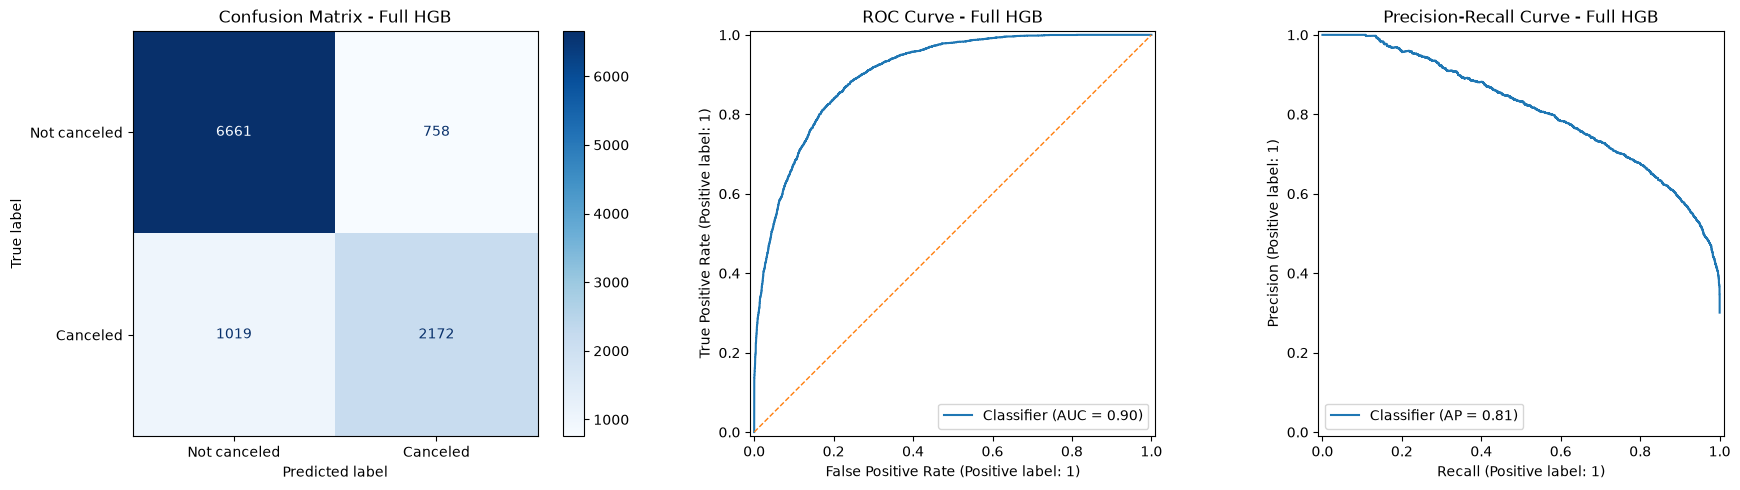

In [10]:
baseline_proba = baseline_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["Not canceled", "Canceled"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
)
axes[0].set_title("Confusion Matrix - Full HGB")

RocCurveDisplay.from_predictions(y_test, baseline_proba, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[1].set_title("ROC Curve - Full HGB")

PrecisionRecallDisplay.from_predictions(y_test, baseline_proba, ax=axes[2])
axes[2].set_title("Precision-Recall Curve - Full HGB")

plt.tight_layout()
plt.show()

## 11. Feature importance graph (permutation importance)

Permutation importance measures how much the test ROC-AUC changes when one feature is shuffled. A larger positive value means the feature was more useful to this fitted model. This is an interpretation step, not a feature-selection step; do not use this test-set graph to make further model choices and then report the same test score as an untouched final evaluation.

,Feature,Importance,Std
0,Agent,0.164945,0.002538
1,Country,0.100661,0.002181
2,TotalOfSpecialRequests,0.057361,0.001158
3,LeadTime,0.051093,0.001464
4,date,0.035717,0.000812
5,AssignedRoomType,0.032702,0.001025
6,RequiredCarParkingSpaces,0.030718,0.001865
7,CustomerType,0.027823,0.001552
8,ReservedRoomType,0.022135,0.001291
9,PreviousCancellations,0.014597,0.001134


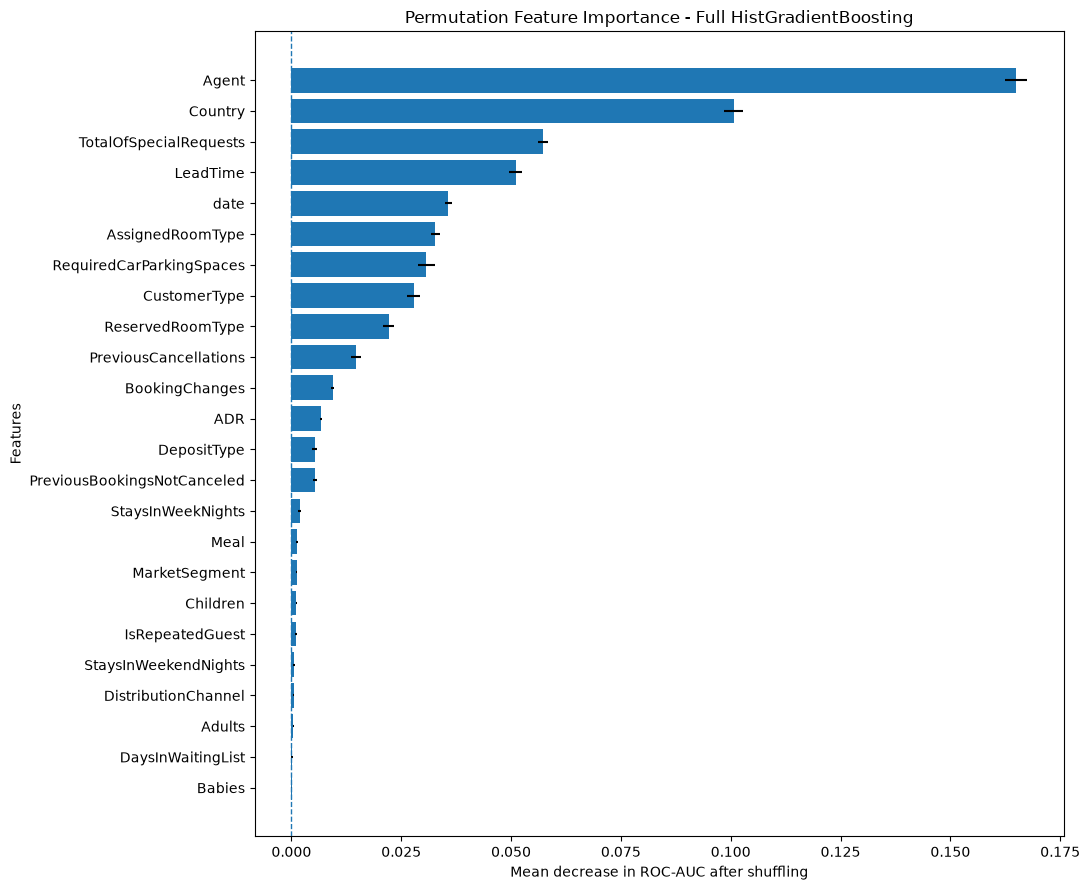

In [11]:
importance_result = permutation_importance(
    baseline_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std,
}).sort_values("Importance", ascending=True)

display(importance_df.sort_values("Importance", ascending=False).reset_index(drop=True))

plt.figure(figsize=(11, 9))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"],
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Mean decrease in ROC-AUC after shuffling")
plt.ylabel("Features")
plt.title("Permutation Feature Importance - Full HistGradientBoosting")
plt.tight_layout()
plt.show()

## 12. Feature ablation: train a model without Agent and Country

This is an experiment to measure how much the full model depends on `Agent` and `Country`. The main model above still contains both. This experiment drops only those two columns from a *separate* copy used for the ablation comparison.

In [12]:
ABLATION_COLUMNS = ["Agent", "Country"]
missing_ablation = [col for col in ABLATION_COLUMNS if col not in X_train.columns]
if missing_ablation:
    raise KeyError(f"Cannot run ablation; columns not found: {missing_ablation}")

X_train_no_agent_country = X_train.drop(columns=ABLATION_COLUMNS).copy()
X_test_no_agent_country = X_test.drop(columns=ABLATION_COLUMNS).copy()

ablation_model = HistGradientBoostingClassifier(
    loss="log_loss",
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    max_bins=MAX_BINS,
    categorical_features="from_dtype",
    early_stopping="auto",
    random_state=42,
    verbose=0,
)

ablation_model.fit(X_train_no_agent_country, y_train)
print("Ablation model trained without:", ABLATION_COLUMNS)
print("All other features, including AssignedRoomType and BookingChanges, remain included.")

ablation_result = classification_metrics(
    ablation_model,
    X_test_no_agent_country,
    y_test,
    "HGB - without Agent/Country",
)

ablation_comparison = pd.DataFrame([baseline_result, ablation_result]).set_index("Model")
display(ablation_comparison.T.rename_axis("Metric"))

Ablation model trained without: ['Agent', 'Country']
All other features, including AssignedRoomType and BookingChanges, remain included.


Model,HGB - all features,HGB - without Agent/Country
Metric,,
Accuracy,0.832516,0.806880
Precision (canceled=1),0.741297,0.731174
Recall (canceled=1),0.680664,0.565967
F1-score (canceled=1),0.709688,0.638050
ROC-AUC,0.903929,0.855369
PR-AUC / Average Precision,0.809374,0.748310


## 13. Hyperparameter tuning (training data only)

`RandomizedSearchCV` uses stratified cross-validation on the training set. The test set is not used to choose hyperparameters. This is a modest search to establish a tuned comparison; increase `N_ITER_SEARCH` if you have time and compute available.

In [13]:
param_distributions = {
    "learning_rate": [0.03, 0.05, 0.08, 0.1],
    "max_iter": [150, 200, 300, 400],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [15, 20, 30, 40],
    "l2_regularization": [0.0, 0.1, 0.5, 1.0, 5.0],
}

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
N_ITER_SEARCH = 8  # Increase for a broader search; it will take longer.

search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(
        loss="log_loss",
        max_bins=MAX_BINS,
        categorical_features="from_dtype",
        early_stopping="auto",
        random_state=42,
        verbose=0,
    ),
    param_distributions=param_distributions,
    n_iter=N_ITER_SEARCH,
    scoring="roc_auc",
    cv=cv_strategy,
    refit=True,
    n_jobs=1,
    random_state=42,
    verbose=1,
    return_train_score=False,
)

search.fit(X_train, y_train)
tuned_model = search.best_estimator_

print("Best cross-validation ROC-AUC:", round(search.best_score_, 5))
print("Best parameters:")
print(search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best cross-validation ROC-AUC: 0.90012
Best parameters:
{'min_samples_leaf': 15, 'max_leaf_nodes': 63, 'max_iter': 400, 'learning_rate': 0.05, 'l2_regularization': 5.0}


## 14. Evaluate the tuned model on the untouched test set

In [14]:
tuned_result = classification_metrics(
    tuned_model, X_test, y_test, "HGB - tuned"
)
tuned_pred = tuned_model.predict(X_test)
tuned_proba = tuned_model.predict_proba(X_test)[:, 1]

print("Classification report - tuned HGB:")
print(classification_report(
    y_test,
    tuned_pred,
    target_names=["Not canceled (0)", "Canceled (1)"],
    zero_division=0,
))

display(pd.DataFrame([baseline_result, tuned_result]).set_index("Model").T.rename_axis("Metric"))

Classification report - tuned HGB:
                  precision    recall  f1-score   support

Not canceled (0)       0.87      0.90      0.88      7419
    Canceled (1)       0.74      0.68      0.71      3191

        accuracy                           0.83     10610
       macro avg       0.81      0.79      0.80     10610
    weighted avg       0.83      0.83      0.83     10610



Model,HGB - all features,HGB - tuned
Metric,,
Accuracy,0.832516,0.833742
Precision (canceled=1),0.741297,0.742605
Recall (canceled=1),0.680664,0.684425
F1-score (canceled=1),0.709688,0.712329
ROC-AUC,0.903929,0.904873
PR-AUC / Average Precision,0.809374,0.811729


## 15. Random Forest comparison

Scikit-learn Random Forest does not natively accept string categorical columns. For this separate benchmark only, categorical columns are One-Hot Encoded inside a pipeline. The main HistGradientBoosting models above continue to use native categorical support and no manual encoding. This comparison does not change the cleaned source data.

In [15]:
# Use the same train/test rows as the HistGradientBoosting models.
X_train_rf = X_train_raw.copy()
X_test_rf = X_test_raw.copy()

# Agent is an ID, so pass it to OneHotEncoder as a category.
for col in categorical_columns:
    X_train_rf[col] = X_train_rf[col].astype("string")
    X_test_rf[col] = X_test_rf[col].astype("string")

# No imputation is applied in this notebook. Stop if the cleaned input unexpectedly
# contains missing predictor values before fitting this Random Forest comparator.
if X_train_rf.isna().any().any() or X_test_rf.isna().any().any():
    raise ValueError(
        "Random Forest comparison found missing predictor values. "
        "This notebook does not impute missing data; inspect the cleaned CSV first."
    )

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numeric", "passthrough", numeric_columns),
    ],
    remainder="drop",
)

rf_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )),
])

rf_model.fit(X_train_rf, y_train)
print("Random Forest comparison model trained.")
rf_result = classification_metrics(rf_model, X_test_rf, y_test, "Random Forest")

Random Forest comparison model trained.


## 16. Compare all model experiments

,Accuracy,Precision (canceled=1),Recall (canceled=1),F1-score (canceled=1),ROC-AUC,PR-AUC / Average Precision
Model,,,,,,
HGB - tuned,0.833742,0.742605,0.684425,0.712329,0.904873,0.811729
HGB - all features,0.832516,0.741297,0.680664,0.709688,0.903929,0.809374
Random Forest,0.830631,0.751262,0.653087,0.698743,0.892992,0.788295
HGB - without Agent/Country,0.806880,0.731174,0.565967,0.638050,0.855369,0.748310


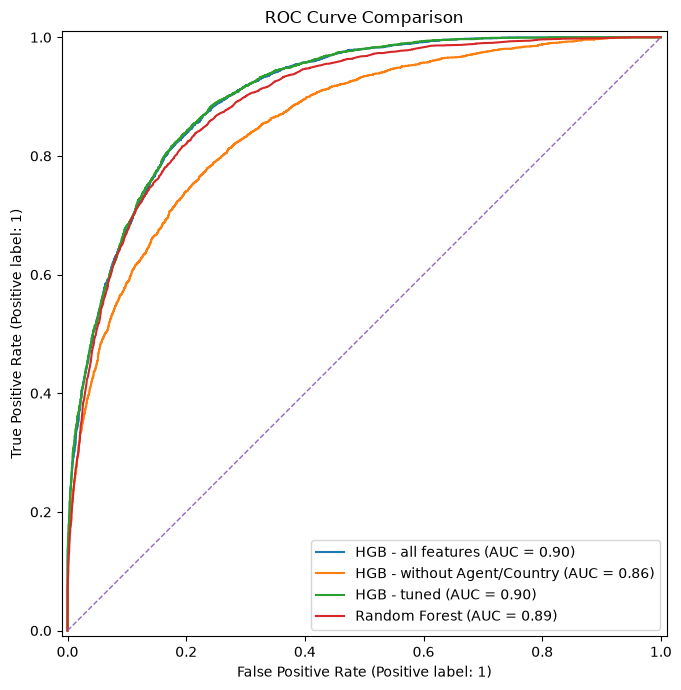

In [16]:
all_results = pd.DataFrame([
    baseline_result,
    ablation_result,
    tuned_result,
    rf_result,
]).set_index("Model")

display(all_results.sort_values("ROC-AUC", ascending=False))

# Compare ROC curves on the same test set.
fig, ax = plt.subplots(figsize=(8, 7))
RocCurveDisplay.from_predictions(y_test, baseline_model.predict_proba(X_test)[:, 1], name="HGB - all features", ax=ax)
RocCurveDisplay.from_predictions(y_test, ablation_model.predict_proba(X_test_no_agent_country)[:, 1], name="HGB - without Agent/Country", ax=ax)
RocCurveDisplay.from_predictions(y_test, tuned_model.predict_proba(X_test)[:, 1], name="HGB - tuned", ax=ax)
RocCurveDisplay.from_predictions(y_test, rf_model.predict_proba(X_test_rf)[:, 1], name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

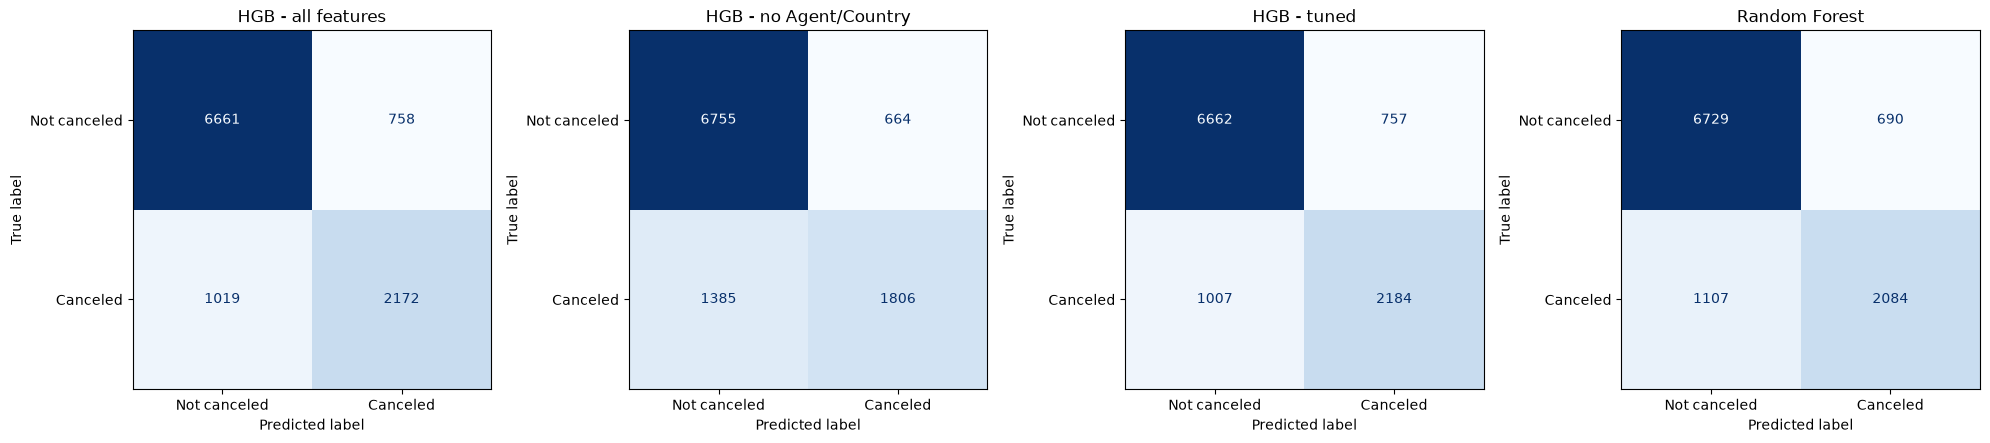

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

model_specs = [
    (baseline_model, X_test, "HGB - all features"),
    (ablation_model, X_test_no_agent_country, "HGB - no Agent/Country"),
    (tuned_model, X_test, "HGB - tuned"),
    (rf_model, X_test_rf, "Random Forest"),
]

for ax, (estimator, X_eval, title) in zip(axes, model_specs):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        estimator.predict(X_eval),
        display_labels=["Not canceled", "Canceled"],
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False,
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [ ]:
# Uncomment to save fitted models for later use.
# import joblib
# joblib.dump(baseline_model, "hgb_full_baseline.joblib")
# joblib.dump(ablation_model, "hgb_without_agent_country.joblib")
# joblib.dump(tuned_model, "hgb_tuned.joblib")
# joblib.dump(rf_model, "random_forest_comparison.joblib")
# print("Models saved.")